# 1

En este proyecto, queremos que te embarques en la creación de un pipeline completo de preparación de datos utilizando el reconocido dataset del Titanic, disponible en Kaggle. Este ejercicio práctico está diseñado para que desarrolles y afiances las habilidades esenciales en la manipulación y limpieza de datos, competencias fundamentales para cualquier profesional en el campo de machine learning.

In [421]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk

data_folder = "../media/1_lab3/"
data_file = "dataset.csv"
seed = 1234

Cargamos los datos.

In [422]:
df = pd.read_csv(data_folder + data_file)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Hay una columna índice, vamos a indicarlo a pandas. Además está la columna nombre, y ticket, que no aportan nada al modelo, por lo que se eliminan.

In [423]:
df = df.set_index("PassengerId")
df = df.drop(columns = ["Name", "Ticket"])
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
PassengerId,,,,,,,,,
1,0,3,male,22.0,1,0,7.2500,NaN,S
2,1,1,female,38.0,1,0,71.2833,C85,C
3,1,3,female,26.0,0,0,7.9250,NaN,S
4,1,1,female,35.0,1,0,53.1000,C123,S
5,0,3,male,35.0,0,0,8.0500,NaN,S


In [424]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Cabin     204 non-null    str    
 8   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(3)
memory usage: 62.8 KB


### Limpieza nulos

Veamos las columnas que tienen valores nulos.

In [427]:
round(df.isna().mean(), 3)

Survived    0.000
Pclass      0.000
Sex         0.000
Age         0.199
SibSp       0.000
Parch       0.000
Fare        0.000
Cabin       0.771
Embarked    0.002
dtype: float64

In [428]:
df.isna().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Cabin       687
Embarked      2
dtype: int64

Hay algunas variables que presentan valores nulos:

- Un 77% de los datos no tienen la variable de cabina, por lo que sería sensato eliminar esta variable, pues no aporta casi información

- Un 0,2% (2 valores) no tienen la variable *Embarked*, entonces eliminaremos esos dos registros.

- El 20% no tiene anotado la edad, decidimos entonces llenar esos valores nulos con la mediana de la edad.

In [429]:
df = df.drop(columns = "Cabin")
indexes = df[df.Embarked.isna() == True].index
df = df.drop(index = indexes)
df.fillna({"Age": df.Age.median()}, inplace = True)

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
PassengerId,,,,,,,,
1,0,3,male,22.0,1,0,7.2500,S
2,1,1,female,38.0,1,0,71.2833,C
3,1,3,female,26.0,0,0,7.9250,S
4,1,1,female,35.0,1,0,53.1000,S
5,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
887,0,2,male,27.0,0,0,13.0000,S
888,1,1,female,19.0,0,0,30.0000,S
889,0,3,female,28.0,1,2,23.4500,S


In [430]:
df.info()

<class 'pandas.DataFrame'>
Index: 889 entries, 1 to 891
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  889 non-null    int64  
 1   Pclass    889 non-null    int64  
 2   Sex       889 non-null    str    
 3   Age       889 non-null    float64
 4   SibSp     889 non-null    int64  
 5   Parch     889 non-null    int64  
 6   Fare      889 non-null    float64
 7   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 62.5 KB


### Transformación de datos

Vamos a procesar las variables categóricas mediante one hot encoding, pues al tener dos variables categóricas, con solo dos categorías una, y tres otra, el aumento de columnas (3) es asumible.

In [431]:
df = pd.get_dummies(df).astype(int)

In [432]:
df.info()

<class 'pandas.DataFrame'>
Index: 889 entries, 1 to 891
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Survived    889 non-null    int64
 1   Pclass      889 non-null    int64
 2   Age         889 non-null    int64
 3   SibSp       889 non-null    int64
 4   Parch       889 non-null    int64
 5   Fare        889 non-null    int64
 6   Sex_female  889 non-null    int64
 7   Sex_male    889 non-null    int64
 8   Embarked_C  889 non-null    int64
 9   Embarked_Q  889 non-null    int64
 10  Embarked_S  889 non-null    int64
dtypes: int64(11)
memory usage: 83.3 KB


Ahora veamos si es necesario estandarizar, para tener una escala adecuada.

In [433]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Survived,889.0,0.382452,0.486260,0.0,0.0,0.0,1.0,1.0
Pclass,889.0,2.311586,0.834700,1.0,2.0,3.0,3.0,3.0
Age,889.0,29.299213,12.993433,0.0,22.0,28.0,35.0,80.0
SibSp,889.0,0.524184,1.103705,0.0,0.0,0.0,1.0,8.0
Parch,889.0,0.382452,0.806761,0.0,0.0,0.0,0.0,6.0
Fare,889.0,31.677165,49.706915,0.0,7.0,14.0,31.0,512.0
Sex_female,889.0,0.350956,0.477538,0.0,0.0,0.0,1.0,1.0
Sex_male,889.0,0.649044,0.477538,0.0,0.0,1.0,1.0,1.0
Embarked_C,889.0,0.188976,0.391710,0.0,0.0,0.0,0.0,1.0
Embarked_Q,889.0,0.086614,0.281427,0.0,0.0,0.0,0.0,1.0


Vamos a estandarizar las columnas *Age* y *Fare*, pues tienen valores promedios alejados al resto de las columnas.

In [434]:
standarize = lambda x: (x - x.mean()) / x.std()
df["Age"] = standarize(df["Age"])
df["Fare"] = standarize(df["Fare"])

In [435]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Survived,889.0,3.824522e-01,0.486260,0.000000,0.000000,0.000000,1.000000,1.000000
Pclass,889.0,2.311586e+00,0.834700,1.000000,2.000000,3.000000,3.000000,3.000000
Age,889.0,2.397782e-17,1.000000,-2.254925,-0.561762,-0.099990,0.438744,3.902032
SibSp,889.0,5.241845e-01,1.103705,0.000000,0.000000,0.000000,1.000000,8.000000
Parch,889.0,3.824522e-01,0.806761,0.000000,0.000000,0.000000,0.000000,6.000000
Fare,889.0,2.197967e-17,1.000000,-0.637279,-0.496453,-0.355628,-0.013623,9.663099
Sex_female,889.0,3.509561e-01,0.477538,0.000000,0.000000,0.000000,1.000000,1.000000
Sex_male,889.0,6.490439e-01,0.477538,0.000000,0.000000,1.000000,1.000000,1.000000
Embarked_C,889.0,1.889764e-01,0.391710,0.000000,0.000000,0.000000,0.000000,1.000000
Embarked_Q,889.0,8.661417e-02,0.281427,0.000000,0.000000,0.000000,0.000000,1.000000


In [436]:
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
PassengerId,,,,,,,,,,,
1,0,3,-0.561762,1,0,-0.496453,0,1,0,0,1
2,1,1,0.669630,1,0,0.791094,1,0,1,0,0
3,1,3,-0.253914,0,0,-0.496453,1,0,0,0,1
4,1,1,0.438744,1,0,0.428971,1,0,0,0,1
5,0,3,0.438744,0,0,-0.476335,0,1,0,0,1


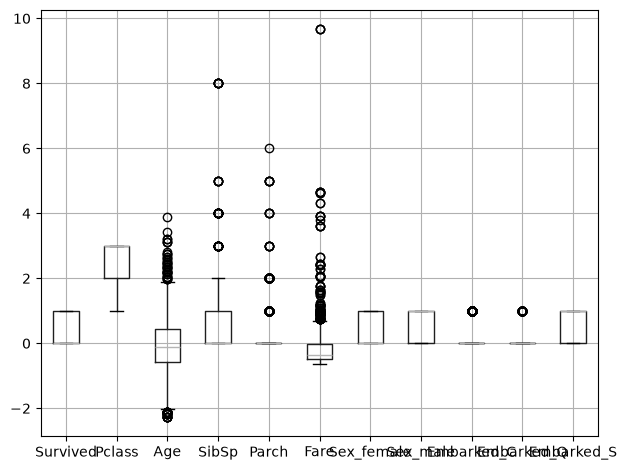

In [437]:
df.boxplot()
plt.tight_layout()

Guardamos el dataset.

In [441]:
df.to_csv(data_folder + "dataset_cleaned.csv")